**Анализ цен на недвижимость в Мельбурне (Melbourne Housing Market)**
Проект посвящен исследованию и прогнозированию цен на жилье в Мельбурне на основе открытого датасета. 
*Цель:* Построить модель машинного обучения (Decision Tree Regressor), способную предсказывать стоимость дома на основе его характеристик (количество комнат, площадь, координаты и т.д.).
*Стек*
Python (Pandas, NumPy)
Scikit-learn (DecisionTreeRegressor, train_test_split, метрики)
Jupyter Notebook (VS Code)

In [1]:
import pandas as  pd 
import numpy as np

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt
import seaborn as sns

**Чтение датасета**

In [2]:
df = pd.read_csv('melb_data.csv')

**Первичный осмотр**
*Цель*: Ознакомиться со струтурой данных, типами признаков, оценить полноту данных с последующей предобработкой перед обучением модели.

In [3]:
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [4]:
print( f'Датасет : {df.shape[0]} строк , {df.shape[1]} колонок')

Датасет : 13580 строк , 21 колонок


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  str    
 1   Address        13580 non-null  str    
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  str    
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  str    
 6   SellerG        13580 non-null  str    
 7   Date           13580 non-null  str    
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  str    
 17  Lattitude      13580 non-null  float64
 18  Longtitude     13

In [6]:
df.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


In [7]:
df.describe( include= 'str').T

,count,unique,top,freq
Suburb,13580,314,Reservoir,359
Address,13580,13378,5 Charles St,3
Type,13580,3,h,9449
Method,13580,5,S,9022
SellerG,13580,268,Nelson,1565
Date,13580,58,27/05/2017,473
CouncilArea,12211,33,Moreland,1163
Regionname,13580,8,Southern Metropolitan,4695


**Этап предобработки данных**

In [8]:
duplicates_count = df.duplicated().sum()
print (f'Количество найденных дубликатов : {duplicates_count}')

Количество найденных дубликатов : 0


In [9]:
is_null_count = df.isna().sum()
is_null_count_filtered = is_null_count[is_null_count>0].sort_values(ascending=False)
total_missing = is_null_count.sum()

print( f"Всего пустых значений в датасете : {total_missing}\n")
print("Количество пустые значений по колонкам")
display(is_null_count_filtered.to_frame(name='Количество пропусков'))


Всего пустых значений в датасете : 13256

Количество пустые значений по колонкам


,Количество пропусков
BuildingArea,6450
YearBuilt,5375
CouncilArea,1369
Car,62


In [10]:
missing_pct = (df.isna().mean() * 100).round(2).sort_values(ascending=False)

print( 'Процент пропущенных значений') 
display(missing_pct[missing_pct > 0].to_frame(name = '%'))

Процент пропущенных значений


,%
BuildingArea,47.50
YearBuilt,39.58
CouncilArea,10.08
Car,0.46


Анализ показал наличие пропусков в колонках `Car`, `BuildingArea`, `YearBuilt` и `CouncilArea`.
было принято решение не удалять их а заполнить медианой т.к. она устойчива к выьросам, чтобы не потерять почти 50% датасета (из-за `BuildingArea`).
Чтобы избежать утечки данных, медиана будет рассчитываться строго по обучающей выборке и применяться к тестовой.

**Разделение данных и обучение базовой модели**

Данные разделены на обучающую (80%) и тестовую (20%) выборки. 
В качестве первой модели используется `DecisionTreeRegressor` с параметрами по умолчанию (`max_depth=None`). 
Во внимание так же принят факт, что дерево без ограничения глубины склонно к переобучению. Это будет проверено на следующем этапе с помощью метрик на тестовой выборке. 

In [11]:
melbourne_features = ['Rooms' , 'Bathroom' , 'Landsize' , 'BuildingArea' , 'YearBuilt' , 'Lattitude', 'Longtitude']
X = df[melbourne_features]
y = df.Price


X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state= 42)
X = X.fillna(X.median())
melbourne_model = DecisionTreeRegressor(random_state=42)
melbourne_model.fit(X_train , y_train)
                                                                                                    

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

**MAE , R^2 , RMSE , MAPE**

In [12]:
# Предсказания на трейне 
train_preds = melbourne_model.predict(X_train)
mae_train = mean_absolute_error(y_train, train_preds)
rmse_train = np.sqrt(mean_squared_error(y_train, train_preds))
r2_train = r2_score(y_train, train_preds)

mape_train = np.mean(np.abs((y_train - train_preds)/ y_train))*100

# Предсказания на тесте
test_preds = melbourne_model.predict(X_test)
mae_test = mean_absolute_error(y_test, test_preds)
rmse_test = np.sqrt(mean_squared_error(y_test, test_preds))
r2_test = r2_score(y_test, test_preds)
mape_test = np.mean(np.abs((y_test - test_preds) / y_test)) * 100
# Вывод
print("МЕТРИКИ ТРЕЙН ")
print(f"MAE:  ${mae_train:,.0f}")
print(f"RMSE: ${rmse_train:,.0f}")
print(f"R^2:   {r2_train:.4f}")
print(f"MAPE: {mape_train:.1f}%")

print("\nМЕТРИКИ ТЕСТ")
print(f"MAE:  ${mae_test:,.0f}")
print(f"RMSE: ${rmse_test:,.0f}")
print(f"R^2:   {r2_test:.4f}")
print(f"MAPE: {mape_test:.1f}%")

МЕТРИКИ ТРЕЙН 
MAE:  $414
RMSE: $5,978
R^2:   0.9999
MAPE: 0.0%

МЕТРИКИ ТЕСТ
MAE:  $248,634
RMSE: $445,929
R^2:   0.4994
MAPE: 22.7%


**Диагностика базовой модели (DecisionTreeRegressor)**
*Метрики качества и их интерпретация*
Для всесторонней оценки модели мы использовали стандартные метрики регрессии:
*MAE (Mean Absolute Error):* Показывает среднюю абсолютную ошибку в долларах. Удобно для понимания реального ущерба.
*RMSE (Root Mean Squared Error):* Сильнее штрафует за крупные промахи (выбросы). Если RMSE сильно больше MAE, значит, модель допускает катастрофические ошибки на отдельных объектах.
*R² (R-squared):* Показывает долю объясненной дисперсии. Значение 1.0 — идеал, 0.0 — модель работает на уровне простого предсказания среднего значения.
*MAPE (Mean Absolute Percentage Error):* Относительная ошибка в процентах. Самый понятный для бизнеса показатель (например, "модель в среднем ошибается на 22%").

**Процесс**
Модель была обучена с параметрами по умолчанию (`max_depth=None`). При оценке качества получены следующие данные:
*Train:* MAE = $414, RMSE = $5,978, R² = 0.9999
*Test:* MAE = $248,634, RMSE = $445,929, R² = 0.4994, MAPE = 22.7%

**Вывод:**
Разница между ошибкой на трейне и тесте указывает на **критическое переобучение (overfitting)**. 
Дерево решений без ограничения глубины зазубрило тренировочную выборку (MAE $414 — это запоминание цены каждого дома), включая случайный шум и выбросы. На новых данных модель теряет способность к обобщению (generalization). 
Кроме того, сильный разрыв между MAE и RMSE на тесте ($248k против $445k) говорит о том, что модель делает большие ошибки на экстремально дорогих объектах недвижимости.

**План улучшения:**
Для решения этой проблемы необходимо ограничить сложность модели с помощью гиперпараметров пред-обрезки (`max_depth` или `max_leaf_nodes`), либо перейти на ансамблевые методы (например, `RandomForestRegressor`), чтобы найти баланс между смещением (bias) и разбросом (variance).

**Эксперимент 1. Обрезка дерева**

In [13]:
print ('\nОграничение по глубине (max_depth)')
best_mae_depth = float('inf')
best_depth = None

for depth in range (2, 21):
    model = DecisionTreeRegressor(max_depth=depth , random_state= 42)
    model.fit(X_train , y_train)
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test , preds)

    if mae < best_mae_depth :
        best_mae_depth = mae
        best_depth = depth

print (f'Лучшая глубина : {best_depth} веток,\nЛучшая MAE : ${best_mae_depth:,.0f}\n___________')

print( '\nОграничение по количеству листьев (max_leaf_nodes)')
best_mae_leaves = float('inf')
best_leaves = None

for leaves in [10 , 20 , 30 ,50, 70 ,100 , 150, 200]: 
    model = DecisionTreeRegressor(max_leaf_nodes=leaves , random_state=42)
    model.fit( X_train , y_train)
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test , preds)

    if mae < best_mae_leaves:
        best_mae_leaves = mae
        best_leaves = leaves

print(f'Лучщее количество листьев : {best_leaves}\nЛучшая MAE : ${best_mae_leaves:,.0f}\n___________')

if best_mae_leaves < best_mae_depth : 
    print (f'\nfПобедил параметр max_leaves = {best_leaves}\n__________')
    final_tree = DecisionTreeRegressor(max_leaf_nodes=best_leaves , random_state= 42)
else:
    print(f'\nПобедил параметр max_depth = {best_depth}\n__________')
    final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42)


final_tree.fit(X_train, y_train)
final_preds = final_tree.predict(X_test)


print('\nМетрики обрезанного дерева')
print(f'MAE: ${mean_absolute_error(y_test , final_preds):,.0f}')
print(f'r^2 : {r2_score(y_test ,final_preds):.4f}')
print(f'MAPE : {np.mean(np.abs((y_test - final_preds)/ y_test)) * 100:.1f}%\n_____')


Ограничение по глубине (max_depth)
Лучшая глубина : 13 веток,
Лучшая MAE : $226,102
___________

Ограничение по количеству листьев (max_leaf_nodes)
Лучщее количество листьев : 200
Лучшая MAE : $231,502
___________

Победил параметр max_depth = 13
__________

Метрики обрезанного дерева
MAE: $226,102
r^2 : 0.6126
MAPE : 20.9%
_____


**Эксперимент 1: Улучшение DecisionTreeRegressor (Pre-pruning)**
Для борьбы с переобучением базовой модели были протестированы два подхода к пред-обрезке дерева: ограничение по глубине (`max_depth`) и ограничение по количеству листьев (`max_leaf_nodes`). 
- В ходе эксперимента лучший результат показал параметр `max_depth` со значением `13`.
- Ошибка MAE снизилась с $248,634 (базовая модель) до $226,102.
- Коэффициент детерминации R² вырос с 0.4994 до  0.6126.
- Это доказывает, что ограничение сложности модели позволяет ей обобщать данные, а не зазубривать их.

**Эксперимент 2. Ансамбль моделей (Random Forest)**
Даже обрезанное одиночное дерево обладает высокой димперсией. Было принято решение использовать модель Random Forest с целью увеличения точности и снижения переобучения.

In [14]:
from sklearn.ensemble import RandomForestRegressor

In [15]:
rf_model = RandomForestRegressor(n_estimators= 100 , random_state= 42)
rf_model.fit(X_train , y_train)

rf_preds = rf_model.predict(X_test)

#Метрики

rf_mae = mean_absolute_error(y_test , rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test , rf_preds))
rf_r2 = r2_score(y_test , rf_preds)
rf_mape = np.mean(np.abs(( y_test -rf_preds)/y_test))*100 

print('Метрики Random Forest')
print(f"_________\nMAE : ${rf_mae:,.0f}") 
print(f'RMSE: $ {rf_rmse:,.0f}')
print(f"r^2 : {rf_r2:,.4f}")
print(f'MAPE : {rf_mape :,.1f}%\n__________')

if rf_mae < best_mae_depth :
    print ("Модель Random Forest обладает меньшей MAE")
else :
    print ('Модель DecisionTree обладает меньшей MAE')

Метрики Random Forest
_________
MAE : $176,744
RMSE: $ 292,505
r^2 : 0.7846
MAPE : 16.6%
__________
Модель Random Forest обладает меньшей MAE


**Сравнение с предыдущими параметрами**
Базовая переобученная модель  *MAE: $248,634* , *RMSE: $445,929* *R^2: 0.4994* *MAPE: 22.7%*
Обрезанное дерево             *MAE: $226,102* , *r^2 : 0.6126* , *MAPE : 20.9%*
Random Forest                 *MAE: $176,744* , *RMSE: $292,505* , *r^2 : 0.7846* , *MAPE : 16.6%*

Random Forest показал наилучший результат. Усреднение множества деревьев позволило модели снизить дисперсию (variance) и  обобщить тестовую выюорку. MAPE в 16.6% означает, что в среднем модель ошибается на 16% от реальной стоимости дома.

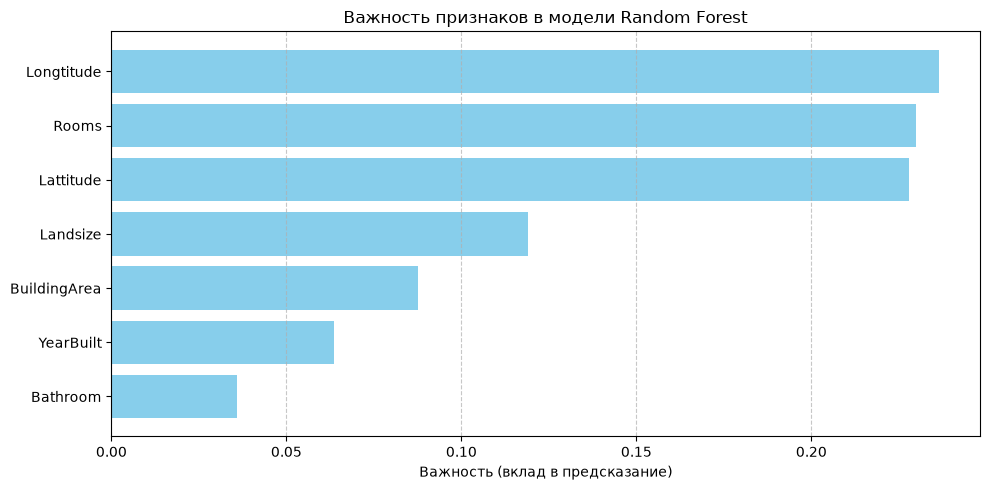

In [16]:
importances = rf_model.feature_importances_
features_names = X_train.columns

features_imp_df = pd.DataFrame({'Признак' : features_names , 'Важность' : importances})
features_imp_df = features_imp_df.sort_values(by= 'Важность'  , ascending= True)

plt.figure(figsize= (10, 5))
plt.barh(features_imp_df ['Признак'] , features_imp_df ['Важность'] , color = "skyblue")
plt.xlabel ('Важность (вклад в предсказание)')
plt.title('Важность признаков в модели Random Forest')
plt.grid(axis = "x" , linestyle = "--" , alpha = 0.7)
plt.tight_layout()
plt.show() 

**Интерпретация модели: Важность признаков (Feature Importance)**

Для понимания того, какие факторы наиболее сильно влияют на стоимость недвижимости, был построен график важности признаков (Feature Importance) на основе модели Random Forest.

**Бизнес-выводы:**
1. Признаки `Longtitude` и `Lattitude` (координаты) оказались самыми важными. Это подтверждает известное правило рынка недвижимости: "главное — это локация". Модель выучила, что дома в престижных районах стоят значительно дороже.
2. Параметры `Rooms` (количество комнат) и `Landsize` (размер участка) также являются критически важными признаками.
3. Второстепенные факторы `YearBuilt` (год постройки) и `Bathroom` (количество ванных) влияют на цену, но в меньшей степени.